In [1]:
import pandas as pd


In [2]:
data = [("img.png", "BARCELONA", "RBC"), ("img2.png", "MUNICH", "WBC")]
df = pd.DataFrame(data, columns=["image_path", "dataset", "cell_type"])
df.head()

,image_path,dataset,cell_type
0,img.png,BARCELONA,RBC
1,img2.png,MUNICH,WBC


In [3]:
import torch

In [ ]:
if not torch.backends.mps.is_available():
    if not torch.backends.mps.is_built():
        print(
            "MPS not available because the current PyTorch install was not built with MPS enabled."
        )
    else:
        print(
            "MPS not available because the current macOS version is not 14.0+ "
            "and/or you do not have an MPS-enabled device on this machine."
        )
else:
    print("mps available")


mps available


In [ ]:
from torchvision import models, transforms
from torchvision.models import ResNet50_Weights

weights = ResNet50_Weights.IMAGENET1K_V1

# Charger le modèle pré-entraîné Resnet50
model = models.resnet50(weights=weights)


# Définir les transformations à appliquer à l'image avant de la passer au modèle
preprocess = transforms.Compose(
    [
        transforms.Resize((224, 224)),  # Redimensionner l'image à 224x224 pixels
        transforms.ToTensor(),  # Convertir l'image en tenseur
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),  # Normaliser les canaux de l'image
    ]
)

In [ ]:
from captum.attr import IntegratedGradients


def compute_ig_heatmap(
    model,
    input_tensor,
    target,
    device,
    n_steps: int = 50,
    baseline=None,
):
    """Calcule une heatmap d'importance des pixels avec Integrated Gradients.

    Args:
        model: le modèle PyTorch (ex: models.resnet50(weights=...))
        input_tensor: tenseur d'entrée déjà pré-traité, de forme (1, C, H, W)
                       (batch de taille 1)
        target: l'indice de la classe cible (int), ou un tenseur d'indices
                si le batch contient plusieurs images
        device: 'cuda' ou 'cpu' (ou un torch.device)
        n_steps: nombre de pas de l'intégration (plus = plus précis mais plus lent)
        baseline: image de référence (même forme que input_tensor). Par défaut,
                  une image noire (zéros), le choix standard pour Integrated Gradients.

    Returns:
        heatmap: array numpy 2D (H, W), importance agrégée sur les canaux,
                 normalisée entre 0 et 1
        attributions: tenseur brut des attributions (1, C, H, W) retourné par Captum
        delta: erreur de convergence de l'approximation (proche de 0 = bon signe)
    """
    model = model.to(device)
    model.eval()

    input_tensor = input_tensor.to(device)
    input_tensor.requires_grad_()

    if baseline is None:
        baseline = torch.zeros_like(input_tensor).to(device)
    else:
        baseline = baseline.to(device)

    ig = IntegratedGradients(model)

    attributions, delta = ig.attribute(
        input_tensor,
        baselines=baseline,
        target=target,
        n_steps=n_steps,
        return_convergence_delta=True,
    )

    # (1, C, H, W) -> (H, W, C) sur CPU, en numpy
    attr_np = attributions.squeeze().cpu().detach().numpy()
    attr_np = np.transpose(attr_np, (1, 2, 0))

    # Agrégation sur les canaux : somme des valeurs absolues
    heatmap = np.sum(np.abs(attr_np), axis=2)

    # Normalisation 0-1 pour l'affichage
    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()

    return heatmap, attributions, delta

/Users/romain/Projects/Liora/Projet/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
import numpy as np
from captum.attr import visualization as viz


def show_heatmap(input_tensor, heatmap, mean, std):
    """Affiche l'image originale, la heatmap et leur superposition,
    via l'utilitaire de visualisation de Captum.

    mean/std doivent être les mêmes valeurs que celles utilisées dans
    transforms.Normalize, pour "dénormaliser" l'image avant affichage.
    """
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)

    img = input_tensor.squeeze().cpu().detach()
    img = img * std + mean  # dénormalisation
    img_np = img.clamp(0, 1).permute(1, 2, 0).numpy()

    _ = viz.visualize_image_attr(
        np.expand_dims(heatmap, axis=2),  # (H, W, 1)
        img_np,
        method="blended_heat_map",
        sign="absolute_value",
        show_colorbar=True,
        title="Integrated Gradients",
    )

In [ ]:
img_path = "/Users/romain/Downloads/smiling-dog-and-cat-close-up-cut-out-stock-png.png"
from PIL import Image

img = Image.open(img_path).convert("RGB")
img_tensor = preprocess(img).unsqueeze(0)
img_tensor.shape

/Users/romain/Projects/Liora/Projet/.venv/lib/python3.14/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


torch.Size([1, 3, 224, 224])

Classe cible : 159, delta de convergence : -0.4751


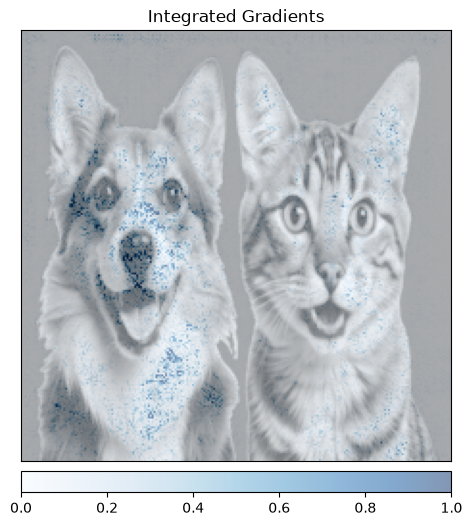

Classe cible : 285, delta de convergence : 1.3537


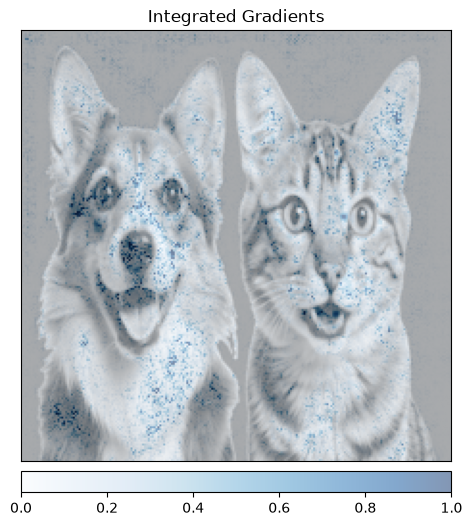

In [ ]:
device = "mps"
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
dog_index = 159  # Chien Rhodesian
cat_index = 285  # Chat Égyptien

target = dog_index

heatmap_dog, attributions, delta = compute_ig_heatmap(model, img_tensor, target, device)

print(f"Classe cible : {target}, delta de convergence : {delta.item():.4f}")
show_heatmap(img_tensor, heatmap_dog, mean, std)

target = cat_index

heatmap_cat, attributions, delta = compute_ig_heatmap(model, img_tensor, target, device)

print(f"Classe cible : {target}, delta de convergence : {delta.item():.4f}")
show_heatmap(img_tensor, heatmap_cat, mean, std)

In [ ]:
{"loss": 0}.update({"metric": 1})

In [ ]:
metrics = {"mae": 2, "toto": 10}
metrics_batch = {name + "_train": 0.0 for name in ["loss"] + list(metrics.keys())}
metrics_batch

{'loss_train': 0.0, 'mae_train': 0.0, 'toto_train': 0.0}

In [ ]:
from collections import OrderedDict

d1 = OrderedDict({"loss_train": 1, "acc_train": 2})
d2 = OrderedDict({"loss_val": 3, "acc_val": 4})
{**d1, **d2}

{'loss_train': 1, 'acc_train': 2, 'loss_val': 3, 'acc_val': 4}

In [ ]:
a = np.array((224, 512))
np.divide(a, 2.0)


array([112., 256.])

In [42]:
a //= 2

In [1]:
BARCELONA_DICT = {
    "BA": "Basophil",
    "EO": "Eosinophil",
    "ERB": "Erythroblast",
    "MMY": "Metamyelocyte",
    "MY": "Myelocyte",
    "PMY": "Promyelocyte",
    "LY": "Lymphocyte",
    "MO": "Monocyte",
    "BNE": "Neutrophil (band)",
    "SNE": "Neutrophil (segmented)",
    "PLATELET": "Platelet",
}
MUNICH_DICT = {
    "BAS": "basophil",
    "EBO": "erythroblast",
    "EOS": "eosinophil",
    "LYA": "Lymphocyte",
    "LYT": "Lymphocyte",
    "MMZ": "Metamyelocyte",
    "MON": "Monocyte",
    "MYB": "Myelocyte",
    "MYO": "Myeloblast",
    "NGB": "Neutrophil (band)",
    "NGS": "Neutrophil (segmented)",
    "PMB": "Promyelocyte",
    "PMO": "Promyelocyte",
}
MAPPING_DICT = {"barcelona": BARCELONA_DICT, "munich": MUNICH_DICT}
CELL_TYPE_TO_IDX = {
    name: i for i, name in enumerate(set(BARCELONA_DICT.values()) | set(MUNICH_DICT.values()))
}
CELL_TYPE_TO_IDX

{'Promyelocyte': 0,
 'Platelet': 1,
 'Erythroblast': 2,
 'Basophil': 3,
 'Lymphocyte': 4,
 'basophil': 5,
 'Myelocyte': 6,
 'erythroblast': 7,
 'Myeloblast': 8,
 'Neutrophil (band)': 9,
 'eosinophil': 10,
 'Metamyelocyte': 11,
 'Neutrophil (segmented)': 12,
 'Monocyte': 13,
 'Eosinophil': 14}